In [6]:
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd


In [7]:
df = pd.read_csv("../DataSet/clean_iris.csv")
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


## predictive KNN

In [8]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler

# split the data into features and target variable
x = df.drop('species', axis=1)
y = df['species']

# split the data into training and testing sets, with 80% of the data used for training and 20% for testing
x_train, x_test, y_train, y_test = train_test_split(x, y, 
test_size=0.2, random_state=42, stratify=y)

# use the standard scaler to scale the features to 
# prevent bias in the model due to different scales of the features
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

# create a KNN classifier and have it look at the 7 nearest neighbors to make a prediction
knn = KNeighborsClassifier(n_neighbors=7)
knn.fit(x_train_scaled, y_train)

y_pred = knn.predict(x_test_scaled)

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Classification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.9666666666666667
Classification Report:
                  precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.91      1.00      0.95        10
 Iris-virginica       1.00      0.90      0.95        10

       accuracy                           0.97        30
      macro avg       0.97      0.97      0.97        30
   weighted avg       0.97      0.97      0.97        30



In [9]:
new_flowers = pd.DataFrame(
    [
        [5.1, 3.5, 1.4, 0.2],
        [6.0, 2.9, 4.5, 1.5],
        [6.5, 3.0, 5.8, 2.2],
    ],
    columns=x.columns
)

new_flowers_scaled = scaler.transform(new_flowers)
new_flowers["Predicted species"] = knn.predict(new_flowers_scaled)

print(new_flowers)

   sepal_length  sepal_width  petal_length  petal_width Predicted species
0           5.1          3.5           1.4          0.2       Iris-setosa
1           6.0          2.9           4.5          1.5   Iris-versicolor
2           6.5          3.0           5.8          2.2    Iris-virginica


In [10]:
import numpy as np
from sklearn.metrics import confusion_matrix

y_pred = knn.predict(x_test_scaled)

# Count correct vs total
correct = (np.array(y_test) == np.array(y_pred)).sum()
print(f"{correct} correct out of {len(y_test)}")   # 29 out of 30

# Show ONLY the flowers it got wrong with their measurements
check = x_test.copy()
check["actual"] = np.array(y_test)
check["predicted"] = y_pred
check["correct"] = check["actual"] == check["predicted"]
print(check[~check["correct"]])

# Confusion matrix shows WHERE the errors land
print(confusion_matrix(y_test, y_pred))

29 correct out of 30
     sepal_length  sepal_width  petal_length  petal_width          actual  \
136           6.0          3.0           4.8          1.8  Iris-virginica   

           predicted  correct  
136  Iris-versicolor    False  
[[10  0  0]
 [ 0 10  0]
 [ 0  1  9]]


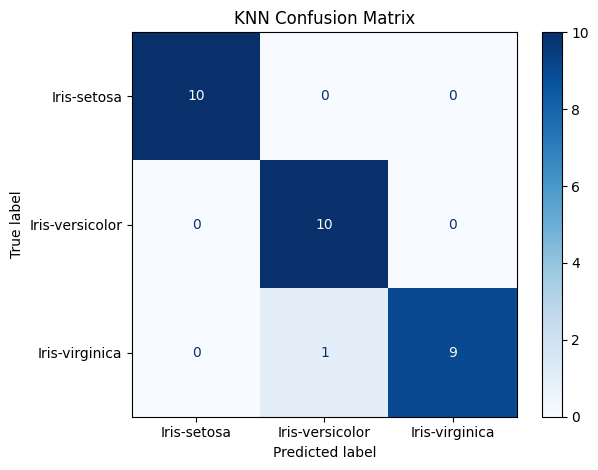

In [11]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

# get the confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=knn.classes_)

# gets the confusion matrix and displays it in a nice format
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=knn.classes_
)
# nice colors
display.plot(cmap="Blues", values_format="d")

plt.title("KNN Confusion Matrix")
plt.tight_layout()
plt.show()

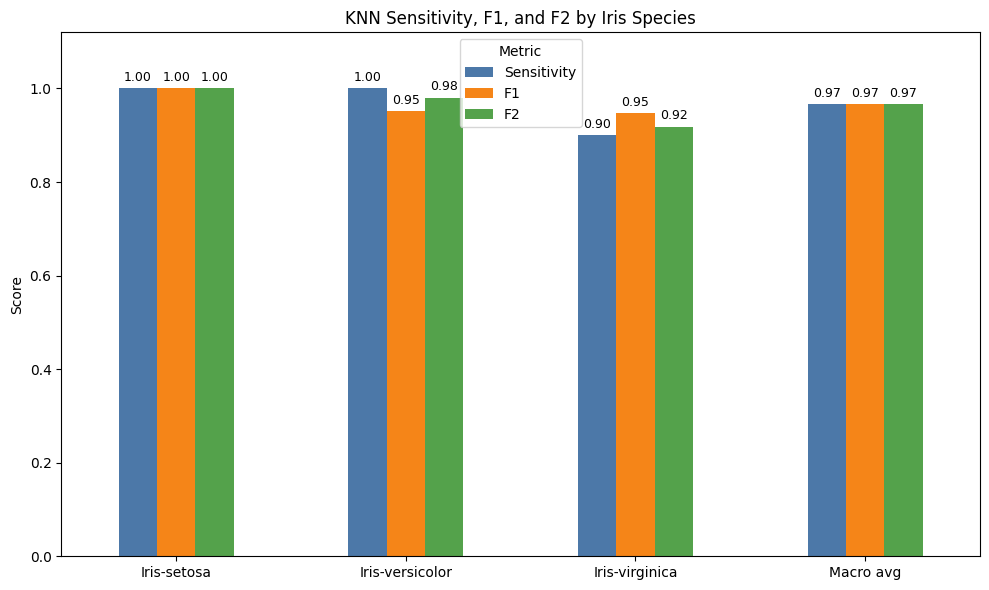

In [12]:
#KNN F1 and F2
from sklearn.metrics import recall_score, fbeta_score
import matplotlib.pyplot as plt

labels = knn.classes_

scores = pd.DataFrame({
    "Sensitivity": recall_score(y_test, y_pred, labels=labels, average=None),
    "F1": fbeta_score(y_test, y_pred, beta=1, labels=labels, average=None),
    "F2": fbeta_score(y_test, y_pred, beta=2, labels=labels, average=None),
}, index=labels)

# Add a single summary row: the unweighted average across species.
scores.loc["Macro avg"] = [
    recall_score(y_test, y_pred, average="macro"),
    fbeta_score(y_test, y_pred, beta=1, average="macro"),
    fbeta_score(y_test, y_pred, beta=2, average="macro"),
]

ax = scores.plot(
    kind="bar",
    figsize=(10, 6),
    color=["#4C78A8", "#F58518", "#54A24B"],
)

for bars in ax.containers:
    ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=9)

ax.set_title("KNN Sensitivity, F1, and F2 by Iris Species")
ax.set_ylabel("Score")
ax.set_xlabel("")
ax.set_ylim(0, 1.12)
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Metric")
plt.tight_layout()
plt.show()

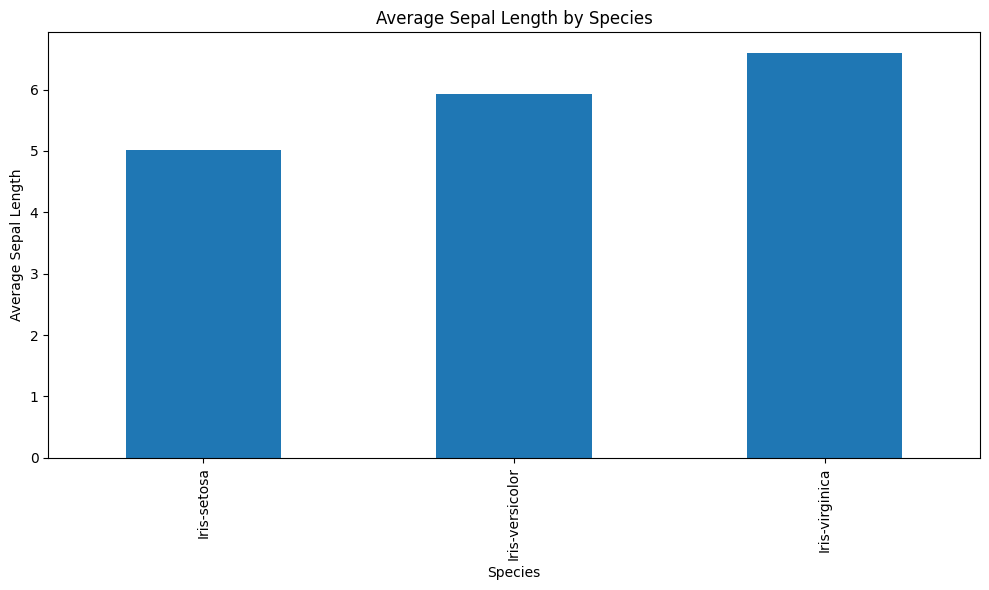

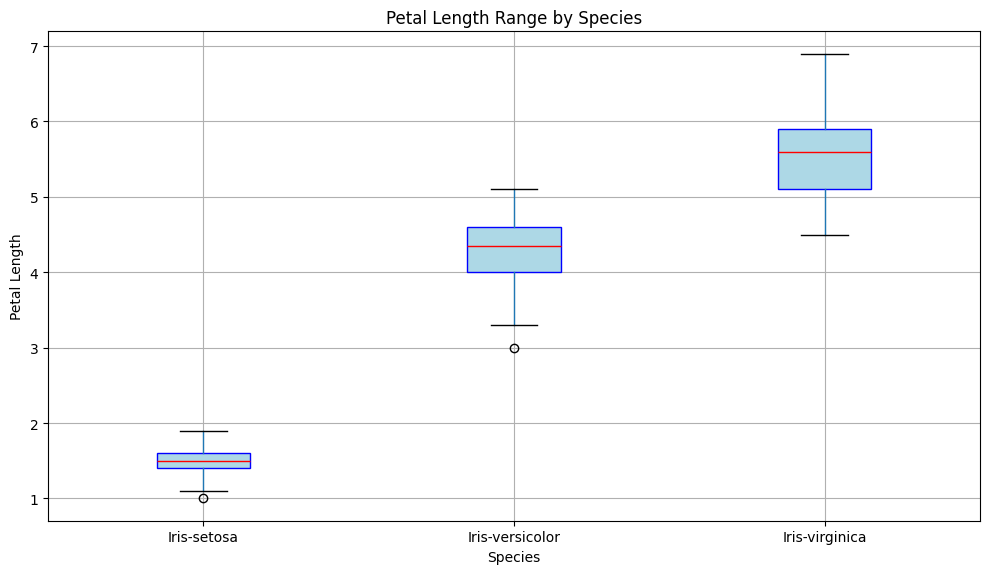

In [13]:

df = pd.read_csv("../DataSet/clean_iris.csv")

mean_sepal_length = df.groupby("species")["sepal_length"].mean()
fig, ax = plt.subplots(figsize=(10, 6))
mean_sepal_length.plot(kind="bar", ax=ax)
ax.set_title("Average Sepal Length by Species")
ax.set_xlabel("Species")
ax.set_ylabel("Average Sepal Length")
fig.tight_layout()
plt.show()

# Compare petal-length ranges with a separate boxplot.
fig, ax = plt.subplots(figsize=(10, 6))
df.boxplot(column="petal_length", by="species", ax=ax, 
grid=True, patch_artist=True, boxprops=dict(facecolor='lightblue', color='blue'), medianprops=dict(color='red'))
ax.set_title("Petal Length Range by Species")
ax.set_xlabel("Species")
ax.set_ylabel("Petal Length")
# add colrs 
fig.suptitle("")
fig.tight_layout()
plt.show()
